# 0 Библиотеки

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [ ]:
x = pd.read_csv("https://github.com/koroteevmv/ML_course/raw/main/ML1.2%20multivariate/data/0_x.csv",header=None)
y = pd.read_csv("https://github.com/koroteevmv/ML_course/raw/main/ML1.2%20multivariate/data/0_y.csv",header=None)
x.head()

,0,1,2,3,4
0,0.071841,0.855352,-0.305597,0.028253,1.826895
1,0.139521,-0.423507,0.461059,-0.447400,-0.034988
2,1.626311,-0.257622,-0.697520,1.413219,1.086292
3,-1.183233,-0.826343,0.073047,-0.639690,-0.503273
4,-0.783365,-0.861232,0.951448,-0.117306,0.680597


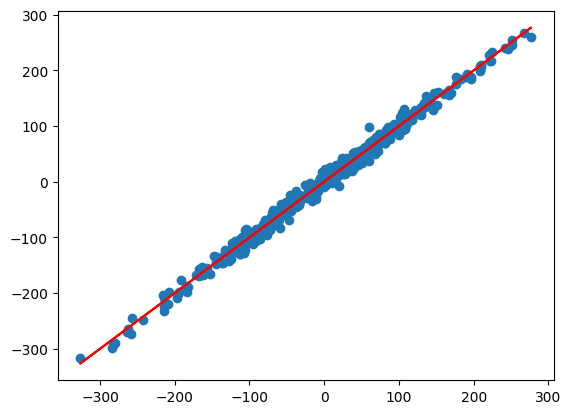

In [ ]:
multiple = LinearRegression()
multiple.fit(x, y)
multiple.score(x, y)
yy = multiple.predict(x)
plt.scatter(yy, y)
plt.plot(yy, yy, c='r')

# 1 Cамостоятельно постройте парные регрессии от каждого атрибута с целевой переменной.

In [ ]:
np.array([1,2,3,4]) * np.array([4,3,2,1])

array([4, 6, 6, 4])

In [ ]:
y.shape

(387, 1)

In [ ]:
x.head()

,0,1,2,3,4
0,0.071841,0.855352,-0.305597,0.028253,1.826895
1,0.139521,-0.423507,0.461059,-0.447400,-0.034988
2,1.626311,-0.257622,-0.697520,1.413219,1.086292
3,-1.183233,-0.826343,0.073047,-0.639690,-0.503273
4,-0.783365,-0.861232,0.951448,-0.117306,0.680597


In [ ]:
np.sum(x,axis=0)

,0
0,31.049209
1,-9.043948
2,-36.453189
3,20.307616
4,26.162585


In [ ]:
np.sum(np.sum(x * np.array([1,2,3,4,5]),axis=0))

115.6451332672574

In [ ]:
x[0]

,0
0,0.071841
1,0.139521
2,1.626311
3,-1.183233
4,-0.783365
...,...
382,0.684004
383,-0.430455
384,-0.457141
385,-0.344278


In [ ]:
class Model:
    """Модель парной линейной регрессии"""
    def __init__(self, X):
        self.b0 = 1
        self.bn = np.repeat(1,X.shape[1]).astype(np.float64)
        self.alpha = 0.1

    def predict(self, X):
        #print(X,self.bn,sep="\n\n\n")
        return self.b0 + np.sum(self.bn * X,axis=1)

    def error(self, X, Y):
        #print(self.predict(X))
        #print(Y)
        #print((self.predict(X)[0] - Y))
        #print((self.predict(X)[0] - Y).values**2)
        return sum(((self.predict(X)[0] - Y).values**2) / (2 * len(X)))

    def plotGraph(self, X, Y):
        '''
        #X0 = np.linspace(X.min(), X.max(), 100)
        Y0 = self.predict(X)
        plt.figure()
        plt.scatter(X, Y)
        plt.plot(X, Y0, 'r')
        plt.show()
        '''
        #for i in X:
        #  plt.scatter(X[i], Y,color='blue')
        #print(self.predict(X).shape)
        #for i in X:
        # plt.scatter(X[i], self.predict(X),color='red')
        plt.scatter(Y,self.predict(X),color='red')
        plt.plot([Y.min(),Y.min()],[Y.max(),Y.max()],color='blue')



    def calc_B(self,X,Y):
      coeff = np.repeat(0,X.shape[1]).astype(np.float64)
      for column in X:
          #print(column)

          #print('column:\n',X[column].shape,'\n',X[column])
          #X[column].shape
          #print((self.predict(X) - Y)[0].shape)
          #print(((self.predict(X) - Y)[0] * X[column]))
          #print(column)
          coeff[column] = sum(((np.sum(self.predict(X)) - Y)[0] * X[column]).values) /len(X)

          #print(coeff)
      #print(coeff)
      return coeff

    def fit(self, X, Y, accuracy=1e-6, max_steps=5000):
        steps, errors = [], []
        step = 0
        old_err = np.inf
        for _ in range(max_steps):
            #dJ0 = sum((self.predict(X) - Y).values) /len(X)
            dJ0 = sum(((np.sum(self.predict(X)) - Y)[0]).values) /len(X)
            #dJ1 = sum(((self.predict(X) - Y) * X).values) /len(X)
            dJ = self.calc_B(X,Y)
            self.b0 -= self.alpha * dJ0
            self.bn -= self.alpha * dJ
            print(self.b0)
            #print(dJ)
            #print(self.bn)
            new_err = self.error(X, Y)
            new_err = new_err#[~np.isnan(new_err)]
            #print( new_err)
            if abs(new_err - old_err) < accuracy:
              break
            step += 1
            steps.append(step)
            errors.append(new_err)
            old_err = new_err
        return steps, errors

    def score(self, X, Y):
        y_pred = self.predict(X)
        ss_res = sum((Y - y_pred)**2)
        ss_total = sum((Y - np.mean(Y))**2)
        r2 = 1 - (ss_res / ss_total)
        return r2



m = Model(x)
m.fit(x,y)
#display(m.predict(x).shape)
#m.plotGraph(x,y)
m.bn,m.predict(x)
#m.calc_B(x,y)

#m.predict(x)

-41.125119699449094
1598.7391095548226
-61681.21409658396
2380751.9030365376
-91889933.39112812
3546679898.274338
-136891361116.14067
5283601931148.099
-203931417868139.5
7871149972249238.0
-3.038031242723851e+17
1.1725902649938747e+19
-4.525851841884369e+20
1.7468450409483105e+22
-6.74230554532516e+23
2.6023306590402764e+25
-1.0044227176379722e+27
3.876774814155668e+28
-1.4963204929310144e+30
5.77535483719596e+31
-2.2291162657397416e+33
8.603729928736303e+34
-3.3207854531566133e+36
1.281725032891199e+38
-4.9470797891454804e+39
1.9094265784109944e+41
-7.369822225915852e+42
2.8445335503187284e+44
-1.097905874911835e+46
4.2375921705365605e+47
-1.635585327861984e+49
6.312875937701893e+50
-2.4365835230932285e+52
9.40449222129119e+53
-3.629856030054989e+55
1.4010171404148174e+57
-5.407512065172398e+58
2.0871398280200062e+60
-8.05574284293067e+61
3.1092786348192232e+63
-1.200089652492723e+65
4.631991349671454e+66
-1.787811753802398e+68
6.900424948463561e+69
-2.663360075136895e+71
1.027978268

<ipython-input-183-9f5e398b6065>:17: RuntimeWarning: overflow encountered in square
  return sum(((self.predict(X)[0] - Y).values**2) / (2 * len(X)))
<ipython-input-183-9f5e398b6065>:17: RuntimeWarning: overflow encountered in square
  return sum(((self.predict(X)[0] - Y).values**2) / (2 * len(X)))
<ipython-input-183-9f5e398b6065>:71: RuntimeWarning: invalid value encountered in subtract
  if abs(new_err - old_err) < accuracy:
<ipython-input-183-9f5e398b6065>:17: RuntimeWarning: overflow encountered in square
  return sum(((self.predict(X)[0] - Y).values**2) / (2 * len(X)))
<ipython-input-183-9f5e398b6065>:71: RuntimeWarning: invalid value encountered in subtract
  if abs(new_err - old_err) < accuracy:
<ipython-input-183-9f5e398b6065>:17: RuntimeWarning: overflow encountered in square
  return sum(((self.predict(X)[0] - Y).values**2) / (2 * len(X)))
<ipython-input-183-9f5e398b6065>:71: RuntimeWarning: invalid value encountered in subtract
  if abs(new_err - old_err) < accuracy:
<ipytho

-1.3740327588555223e+176
5.303360328092337e+177
-2.0469403359065735e+179
7.900584685084903e+180
-3.0493921718804485e+182
1.1769752478548026e+184
-4.5427765796638257e+185
1.7533774894888953e+187
-6.767518865904459e+188
2.612062255557012e+190
-1.0081788262578815e+192
3.891272283240358e+193
-1.5019160874978917e+195
5.796952178341372e+196
-2.2374522010720507e+198
8.635904175277388e+199


<ipython-input-183-9f5e398b6065>:17: RuntimeWarning: overflow encountered in square
  return sum(((self.predict(X)[0] - Y).values**2) / (2 * len(X)))
<ipython-input-183-9f5e398b6065>:71: RuntimeWarning: invalid value encountered in subtract
  if abs(new_err - old_err) < accuracy:
<ipython-input-183-9f5e398b6065>:17: RuntimeWarning: overflow encountered in square
  return sum(((self.predict(X)[0] - Y).values**2) / (2 * len(X)))
<ipython-input-183-9f5e398b6065>:71: RuntimeWarning: invalid value encountered in subtract
  if abs(new_err - old_err) < accuracy:
<ipython-input-183-9f5e398b6065>:17: RuntimeWarning: overflow encountered in square
  return sum(((self.predict(X)[0] - Y).values**2) / (2 * len(X)))
<ipython-input-183-9f5e398b6065>:71: RuntimeWarning: invalid value encountered in subtract
  if abs(new_err - old_err) < accuracy:
<ipython-input-183-9f5e398b6065>:17: RuntimeWarning: overflow encountered in square
  return sum(((self.predict(X)[0] - Y).values**2) / (2 * len(X)))
<ipytho

-3.33320376135144e+201
1.2865181328080652e+203
-4.965579738134219e+204
1.9165670119200578e+206
-7.397382188772126e+207
2.855170881394951e+209
-1.1020115703010284e+211
4.253438941223717e+212
-1.6417017129662672e+214
6.336483376392299e+215
-2.4456952966656834e+217
9.439660974125656e+218
-3.643430129170853e+220
1.406256341465623e+222
-5.427733832684565e+223
2.0949448325875576e+225
-8.085867853646393e+226


...

-2.922129863391366e+255
1.1278557582536474e+257
-4.353189867987563e+258
1.6802026223718504e+260
-6.485085507033694e+261
2.503051326879258e+263
-9.661038298102352e+264
3.728875233004849e+266
-1.4392356260556341e+268
5.555024123557429e+269
-2.1440751225617606e+271
8.27549625157031e+272
-3.19409695533096e+274
1.232827017246094e+276
-4.758347901478838e+277
1.8365816480957347e+279
-7.088662325581077e+280


<ipython-input-183-9f5e398b6065>:17: RuntimeWarning: overflow encountered in square
  return sum(((self.predict(X)[0] - Y).values**2) / (2 * len(X)))
<ipython-input-183-9f5e398b6065>:71: RuntimeWarning: invalid value encountered in subtract
  if abs(new_err - old_err) < accuracy:
<ipython-input-183-9f5e398b6065>:17: RuntimeWarning: overflow encountered in square
  return sum(((self.predict(X)[0] - Y).values**2) / (2 * len(X)))
<ipython-input-183-9f5e398b6065>:71: RuntimeWarning: invalid value encountered in subtract
  if abs(new_err - old_err) < accuracy:
<ipython-input-183-9f5e398b6065>:17: RuntimeWarning: overflow encountered in square
  return sum(((self.predict(X)[0] - Y).values**2) / (2 * len(X)))
<ipython-input-183-9f5e398b6065>:71: RuntimeWarning: invalid value encountered in subtract
  if abs(new_err - old_err) < accuracy:
<ipython-input-183-9f5e398b6065>:17: RuntimeWarning: overflow encountered in square
  return sum(((self.predict(X)[0] - Y).values**2) / (2 * len(X)))
<ipytho

2.7360141389963973e+282
-1.0560205896356467e+284
4.0759273493502384e+285
-1.573187485190343e+287
6.072038707839207e+288
-2.3436274707611423e+290
9.045709334189865e+291
-3.491376440133424e+293
1.3475681117284673e+295
-5.201214612303473e+296
2.007515108719836e+298
-7.748414961007686e+299
2.9906591560475107e+301
-1.1543060397074574e+303
4.4552801365236745e+304


<ipython-input-183-9f5e398b6065>:17: RuntimeWarning: overflow encountered in square
  return sum(((self.predict(X)[0] - Y).values**2) / (2 * len(X)))
<ipython-input-183-9f5e398b6065>:71: RuntimeWarning: invalid value encountered in subtract
  if abs(new_err - old_err) < accuracy:
<ipython-input-183-9f5e398b6065>:17: RuntimeWarning: overflow encountered in square
  return sum(((self.predict(X)[0] - Y).values**2) / (2 * len(X)))
<ipython-input-183-9f5e398b6065>:71: RuntimeWarning: invalid value encountered in subtract
  if abs(new_err - old_err) < accuracy:
<ipython-input-183-9f5e398b6065>:17: RuntimeWarning: overflow encountered in square
  return sum(((self.predict(X)[0] - Y).values**2) / (2 * len(X)))
<ipython-input-183-9f5e398b6065>:71: RuntimeWarning: invalid value encountered in subtract
  if abs(new_err - old_err) < accuracy:
<ipython-input-183-9f5e398b6065>:17: RuntimeWarning: overflow encountered in square
  return sum(((self.predict(X)[0] - Y).values**2) / (2 * len(X)))
<ipytho

-inf
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan


In [ ]:
np.sum(x*m.bn,axis=1) + m.b0

# 2 (*) Модифицируйте код из предыдущей работы так, чтобы модель регрессии умела работать с входными данными, состоящими из произвольного количества столбцов.

# 5 Используйте другие метрики качества регрессионной модели в дополнение к коэффициенту детерминации.

# 6 (*) Замерьте время обучения полиномиальных моделей с разной степенью полинома. Сделайте вывод.